In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ogstools as ot


In [ ]:
def calculate_k(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    k01=factors['k01']
    k02=factors['k02']

    prev=np.linspace(p1,p2,300)

    tanh_term = np.tanh((prev - pjack) / wr)
    c=(k02 - k01) * 0.5
    k_value = k01 + c* (1 + tanh_term)

    # sf0=factors['sf0']
    # beta_dimen=factors['b_dim']
    # beta=pjack*beta_dimen

    # X= np.sqrt(3)*np.sqrt(k_value)/k_value
    # Y= c*(1-tanh_term**2)/wr
    # s_value=  sf0 + beta*X*Y

    # keff=k_value*s_value/sf0
    return prev, k_value

In [ ]:
def calculate_function_k_s(factors):
    pjack=factors['pjack']
    pst=factors['pst']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    ws= max(factors['ws'], 1e-6)
    s_plat = factors["s_plat"]
    sf0 = factors["sf0"]
    k01 = factors["k01"]
    k02 = factors["k02"]

    prev=np.linspace(p1,p2,300)

    u_ = (prev-pjack)/wr 
    tanh_u = np.tanh(u_)
    c=(k02 - k01) * 0.5
    k_value = (k01 + c* (1 + tanh_u)) #permeability base
    
    #dk_X = 3.0/(np.sqrt(3.0*k_value))
    dk_Y = (c/wr)*(1-tanh_u**2)
    dk_dp =dk_Y          #dk_dp

    dk_dp_num = np.gradient(k_value, prev)
    #---------------------------------------------

    alpha = 1.0/ws

    tanh_t1 = np.tanh( alpha * (pst - prev)) 
    term_A = 0.5 * (sf0-s_plat) * ( 1 + tanh_t1)
   
    s_ab = s_plat + term_A 

    ds_term_A = 0.5 *  (s_plat - sf0) *alpha  * ( 1- tanh_t1**2) 
    # ds_ab = ds_term_A + ds_term_B

    # ds_dp_ab_num = np.gradient(s_ab, prev)

    return prev, s_ab, ds_term_A

In [67]:
def calculate_function_k_s_1(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    s_plat = factors["s_plat"]
    b_spike = factors["b_spike"]
    w_spike = factors["w_spike"]
    sf0 = factors["sf0"]
    k01 = factors["k01"]
    k02 = factors["k02"]

    prev=np.linspace(p1,p2,300)

    u_ = (prev-pjack)/wr 
    tanh_u = np.tanh(u_)
    c=(k02 - k01) * 0.5
    k_value = (k01 + c* (1 + tanh_u)) #permeability base
    
    #dk_X = 3.0/(np.sqrt(3.0*k_value))
    dk_Y = (c/wr)*(1-tanh_u**2)
    dk_dp =dk_Y          #dk_dp

    dk_dp_num = np.gradient(k_value, prev)
    #---------------------------------------------
    factor_spike = b_spike
    hs = factor_spike *s_plat
    
    beta = 1.0/w_spike
    alpha = 1.0/wr

    tanh_t1 = np.tanh( 0.5 * alpha * (pjack - prev)) 
    tanh_t2 = np.tanh ( beta * (1.5*pjack - prev))
    term_A = 0.5 * s_plat * ( 1 + tanh_t1)
    term_B = hs * ( 1 - tanh_t2**2)

    s_ab = sf0 + term_A + term_B  

    ds_term_A = s_plat * ( 1- tanh_t1**2) * alpha / 4
    ds_term_B = -2 * hs * beta * tanh_t2 * (1 - tanh_t2**2)
    ds_ab = ds_term_A + ds_term_B

    # ds_dp_ab_num = np.gradient(s_ab, prev)

    return prev, term_A, term_B, s_ab

In [159]:
def calculate_function_k_s_2(factors):
    pjack=factors['pjack']
    ptail=factors['ptail']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    s_plat = factors["s_plat"]
    a_spike = factors["a_spike"]
    w_spike = factors["w_spike"]
    b_tail = factors["b_tail"]
    w_tail = factors["w_tail"]
    sf0 = factors["sf0"]
    k01 = factors["k01"]
    k02 = factors["k02"]

    prev=np.linspace(p1,p2,300)

    u_ = (prev-pjack)/wr 
    tanh_u = np.tanh(u_)
    c=(k02 - k01) * 0.5
    k_value = (k01 + c* (1 + tanh_u)) #permeability base
    
    #dk_X = 3.0/(np.sqrt(3.0*k_value))
    dk_Y = (c/wr)*(1-tanh_u**2)
    dk_dp =dk_Y          #dk_dp

    dk_dp_num = np.gradient(k_value, prev)
    #---------------------------------------------
    delta_s = np.abs(sf0 - s_plat)
    factor_spike = a_spike
    ha = factor_spike*sf0
    factor_tail = b_tail
    hb = factor_tail*s_plat
    alpha = 1.0/wr
    beta = 1.0/w_spike
    omega = 1.0/w_tail

    tanh_t1 = np.tanh( 0.5 * alpha * (pjack - prev)) 
    sech2_t1 = (1-tanh_t1**2)
    tanh_t2 = np.tanh ( beta * (prev - pjack))
    sech2_t2 = (1-tanh_t2**2)
    tanh_t3 = np.tanh ( omega * (ptail -prev ))
    sech2_t3 = (1 - tanh_t3**2)

    term_A = 0.5 * delta_s * ( 1 + tanh_t1)
    term_B = ha * sech2_t2
    term_C = hb*(1 - tanh_t3)

    s_ab = s_plat + term_A + term_B + term_C

    ds_term_A = -0.25 * delta_s * sech2_t1 *  alpha
    ds_term_B = ha * -2 * sech2_t2 * tanh_t2 * beta
    ds_term_C = hb * sech2_t3 * omega


    ds_abc = ds_term_A + ds_term_B + ds_term_C

    ds_dp_ab_num = np.gradient(s_ab, prev)

    return prev, s_ab, ds_abc, ds_dp_ab_num

In [39]:
factors={
         'sf0': 1.0e-8,
         's_plat': 8.5e-11, 
         'pjack':3.1e6,
         'pst': 3.5e6,
         'ptail':6e6,
         'wr':0.5e6,
         'w_spike': 1.0e6,
         'ws': 1.5e6,
         'w_tail': 0.5e6,
         'L':1.0,
         'a_spike': 0.5,
         'b_tail': 2,
         'k01':2e-14,
         'k02':1.0e-9,
         'sma':1.0e-10,
         'b_dim':1.0,
         'p1':1.0,
         'p2':12.0e6,
         'keff':1.0
}

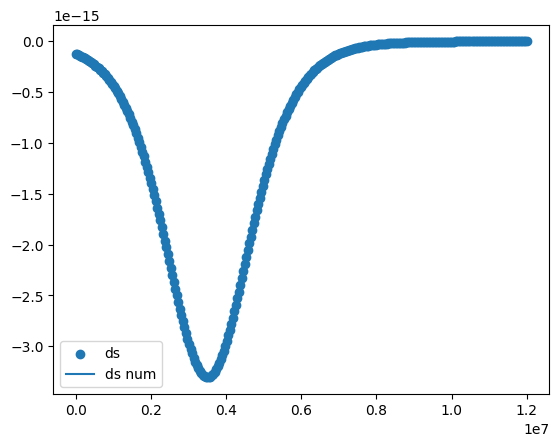

In [44]:
prev, s, ds, dsnum= calculate_function_k_s(factors)

# plt.plot(prev,s, label= "s")
plt.scatter(prev,ds, label = "ds")
plt.plot(prev,dsnum, label = "ds num")



plt.legend()
plt.pause(1)

In [41]:
print(s.min(),s.max())

8.511865427580825e-11 9.907632141083927e-09


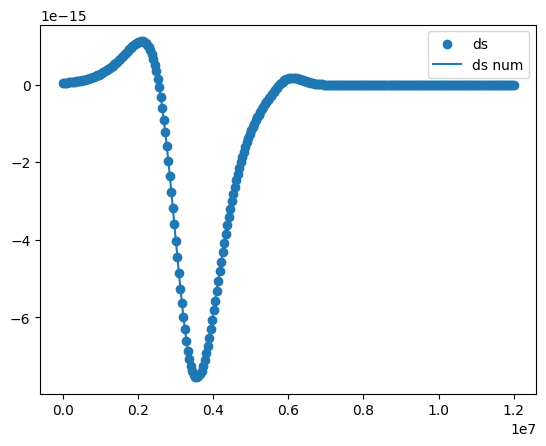

In [162]:
prev, s, ds, ds_num= calculate_function_k_s_2(factors)

# plt.plot(prev,s, label= "s")
plt.scatter(prev,ds, label = "ds")
plt.plot(prev,ds_num, label = "ds num")



plt.legend()
plt.pause(1)

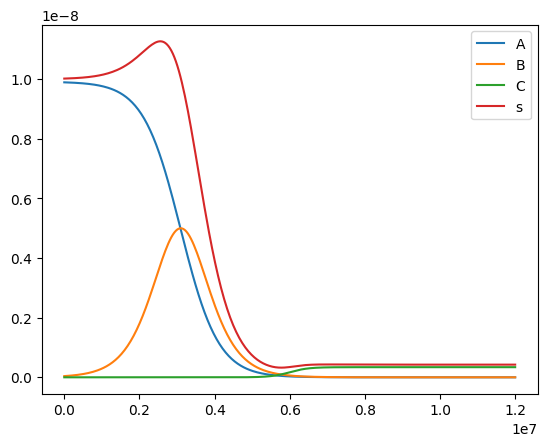

In [147]:
prev, sa, sb,sc, s= calculate_function_k_s_2(factors)

plt.plot(prev,sa, label= "A")
plt.plot(prev,sb, label = "B")
plt.plot(prev,sc, label = "C")
plt.plot(prev,s, label = "s")


plt.legend()
plt.pause(1)

In [148]:
print( s[0], s[-1])
print(sc.min())
print((8.5e-11)/2)

1.0020343358123366e-08 4.250005564641611e-10
1.2835518203857533e-20
4.25e-11


In [129]:
s.min()

np.float64(9.56237441978645e-09)

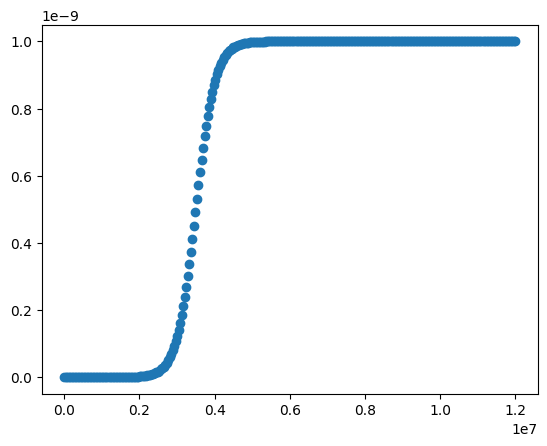

In [9]:
prev, kvalues = calculate_k(factors)

plt.scatter(prev, kvalues)

plt.pause(1)

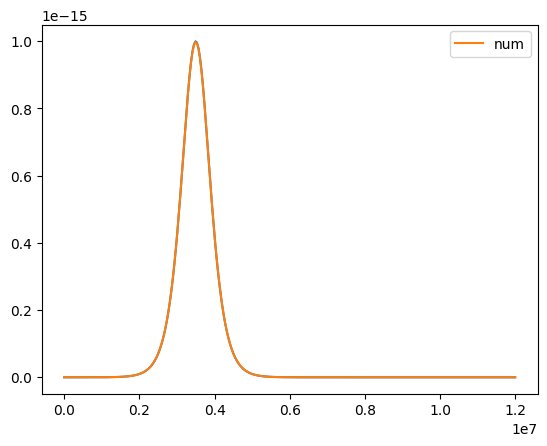

In [69]:
# plt.plot(prev, k)
plt.plot(prev,dk)
plt.plot(prev,dknum, label= "num")

plt.legend()
plt.pause(1)

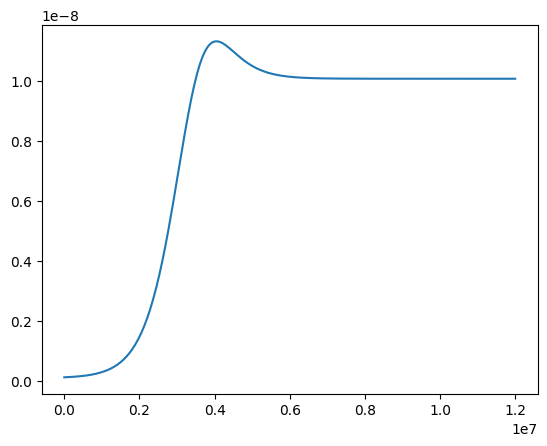

In [91]:
plt.plot(prev, s_ab)
# plt.plot(prev,ds1)
# plt.plot(prev,ds2)

plt.pause(1)

In [4]:
# pvalue, s2, ds, dsnum, dsnum2= 
prev,s2,ds_dp, val_dict = calculate_function_k_s(factors)

In [5]:
# # plt.plot(pvalue, s2)
# plt.plot(pvalue, ds)
# # plt.plot(pvalue, dsnum)
# plt.plot(pvalue, dsnum2)

# plt.pause(1)

In [80]:
def temp_prj(prj_in, prj_out, factors:dict): 


    k_xml, dk_xml, s_xml, ds_xml = ogs_expr_ready( factors)

    model = ot.Project(input_file=prj_in,output_file=prj_out)
    medium=1
    xpath_k=f".//media/medium[@id='{medium}']/properties/property[name='permeability']/value/expression"
    xpath_dk=f".//media/medium[@id='{medium}']/properties/property[name='permeability']/dvalue/expression"

    xpath_s=f".//media/medium[@id='{medium}']/properties/property[name='storage']/value/expression"
    xpath_ds=f".//media/medium[@id='{medium}']/properties/property[name='storage']/dvalue/expression"
    try:
        model.replace_text(k_xml,xpath=xpath_k)
        model.replace_text(dk_xml,xpath=xpath_dk)
        model.replace_text(s_xml,xpath=xpath_s)
        model.replace_text(ds_xml,xpath=xpath_ds)
 

        # nodes = model.tree.getroot().findall(xpath_s)
        # print(f"found {len(nodes)} nodes(s) matchin xpath_s")

    except Exception as e:
        print(f"CRITICAL ERROR in PRJ update: {e}")
        raise # Stop the loop if the input file is not correctly updated

    model.write_input()

In [53]:
def  ogs_expr_ready(factors: dict) -> None:
    "s(p) inverted sigmoid unlinked transition"
    pst=factors['pst']
    ws= max(factors['ws'], 1e-6)
    s_plat = factors["s_plat"]
    sf0 = factors["sf0"]

    prev= "liquid_phase_pressure"

    alpha = f'(1.0 / {ws})'

    tanh_t1 = f'tanh({alpha} * ({pst} - {prev})) '
    term_A = f'(0.5 * ({sf0} - {s_plat}) * ( 1 + {tanh_t1}))'
   
    s_ab = f'({s_plat} + {term_A})'
    s_xml = s_ab 

    ds_term_A = f'(0.5 *  ({s_plat} - {sf0}) * {alpha}  * ( 1- pow({tanh_t1},2)))' 
    ds_xml = ds_term_A
       
    return s_xml, ds_xml

In [72]:
def  ogs_expr_ready(factors: dict) -> None:
    pjack=factors['pjack']
    wr=max(factors['wr'], 1e-6)
    s_plat = factors["s_plat"]
    b_spike = factors["b_spike"]
    w_spike = factors["w_spike"]
    sf0 = factors["sf0"]
    k01 = factors["k01"]
    k02 = factors["k02"]

    prev= "liquid_phase_pressure"

    u_ = f'({prev}-{pjack})/{wr}' 
    tanh_u = f'tanh({u_})'
    c=f'({k02} - {k01}) * 0.5'
    k_value = f'({k01} + {c}* (1 + {tanh_u}))' 
    k_xml = k_value
    dk_dp = f'({c}/{wr})*(1-pow({tanh_u},2))'
    dk_xml = dk_dp
        
    factor_spike = f'{b_spike}'
    hs = f'({factor_spike} *{s_plat})'
    
    beta = f'(1.0 / {w_spike})'
    alpha = f'(1.0 / {wr})'
    
    tanh_t1 = f'(tanh( 0.5 * {alpha} * ({prev} - {pjack})))' 
    tanh_t2 = f'(tanh( {beta} * ({prev} - {pjack})))'
    term_A = f'(0.5 * {s_plat} * ( 1 + {tanh_t1}))'
    term_B = f'({hs} * ( 1 - pow({tanh_t2},2)))'

    s_ab = f'({sf0} + {term_A} + {term_B})'
    s_xml = s_ab

    ds_term_A = f'({s_plat} * ( 1- pow({tanh_t1}, 2)) * {alpha} / 4)'
    ds_term_B = f'(-2 * {hs} * {beta} * {tanh_t2} * (1 - pow({tanh_t2}, 2)))'
    ds_ab = f'({ds_term_A} + {ds_term_B})'
    ds_xml = ds_ab
       
    return k_xml, dk_xml, s_xml, ds_xml

In [54]:
s_xml, ds_xml = ogs_expr_ready(factors)

print(s_xml)
print("\n",ds_xml)


(8.5e-11 + (0.5 * (1e-08 - 8.5e-11) * ( 1 + tanh((1.0 / 1500000.0) * (3500000.0 - liquid_phase_pressure)) )))

 (0.5 *  (8.5e-11 - 1e-08) * (1.0 / 1500000.0)  * ( 1- pow(tanh((1.0 / 1500000.0) * (3500000.0 - liquid_phase_pressure)) ,2)))


# Testing expression


In [51]:
def eval_exprtk_in_python(script_str, params):
    clean_script = script_str.replace("&lt;", "<").replace("&gt;", ">")

    lines = [line.strip() for line in clean_script.strip().splitlines() if line.strip()]
    statements, final_expr = lines[:-1], lines[-1]

    local_scope = {**params,
                   "tanh": np.tanh,
                    "pow": np.pow,
                    "sqrt": np.sqrt}

    for line in statements:
        line = line.rstrip(";").removeprefix("var ").strip()
        var_name, expr = line.split(":=", 1)
        var_name, expr = var_name.strip(), expr.strip()

        if "?" in expr and ":" in expr:
            expr = "np.where( liquid_phase_pressure < pstart, 1.0, np.where(liquid_phase_pressure > pend, 0.0, (pend-liquid_phase_pressure) / (pend - pstart)))"

        local_scope[var_name] = eval(expr, {"__builtins__": {}, "np": np}, local_scope)

    return eval(final_expr, {"__builtins__": {}}, local_scope)

# test
# params = {
#     "liquid_phase_pressure": prev,
#     "pjack": factors["pjack"],
#     "w": factors["wr"], 
#     "k01": factors["k01"], 
#     "k02": factors["k02"],
#     "sf0": factors["sf0"], 
#     "C0": val_dict["C0"], 
#     "pstart": val_dict["pstart"], 
#     "pend": val_dict["pend"],
#     "s_zero": val_dict["s_zero"], 
#     "A": val_dict["A"], 
#     "sa_min": val_dict["sa_min"]
# }

# exprtk_val_s = eval_exprtk_in_python(str(s_xml), params)
# print("Evaluated Script Result:", exprtk_val_s)

# exprtk_val_ds = eval_exprtk_in_python(str(ds_xml), params)
# print("Evaluated Script Result:", exprtk_val_ds)
import math 
import re
import ast

class ExprTkTop(ast.NodeTransformer):
    def visit_name(self, node):
        if node.id == "liquid_phase_pressure":
            return ast.Name(id="p", ctx=node.ctx)
        elif node.id in ("tanh", "sqrt"):
            return ast.Name(id=node.id, ctx=node.ctx)
        return self.generic_visit(node)

def exptrk_eval(exp_str, p_vec):
    expr_py = exp_str.replace("&lt;", "<")
    expr_py = expr_py.replace("&gt;", ">")
    expr_py = expr_py.replace("?", " if ").replace(":", " else ")
    expr_py = expr_py.replace("liquid_phase_pressure", "p")
    tree = ast.parse(expr_py, mode = "eval")

    transformed_tree = ExprTkTop().visit(tree)
    ast.fix_missing_locations(transformed_tree)

    compile_code = compile(transformed_tree, filename="<ogs_expr>", mode="eval")

    eval_namespace = {
        "p": float(p_vec), 
        "tanh": math.tanh,
        "sqrt": math.sqrt,
    }


    return eval(compile_code, eval_namespace)


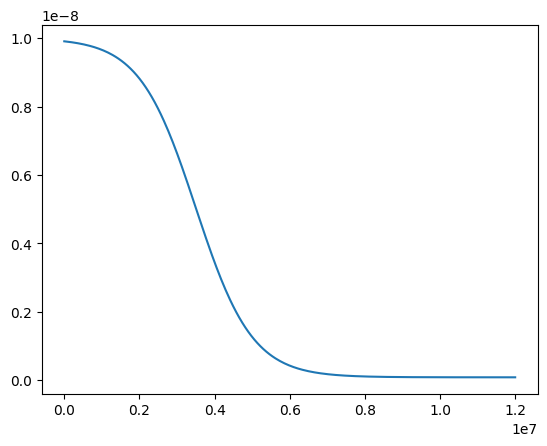

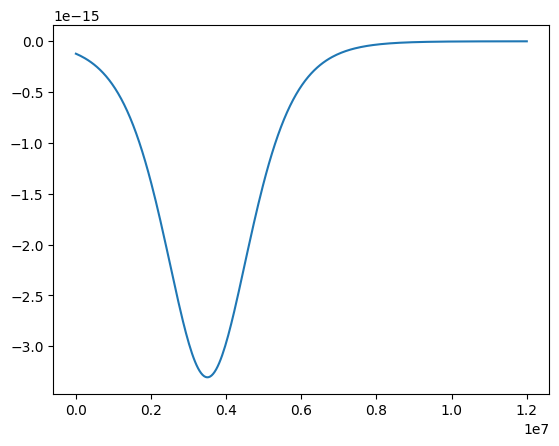

In [55]:
p_array = np.linspace(1.0,12.0e6,300)
result_s = np.array([exptrk_eval(s_xml, p) for p in p_array])
result_ds = np.array([exptrk_eval(ds_xml, p) for p in p_array])
plt.plot(p_array,result_s)
plt.pause(1)
plt.plot(p_array,result_ds)
plt.pause(1)

In [65]:
p_array = np.linspace(1.0,12.0e6,300)
result_k= np.array([exptrk_eval(k_xml, p) for p in p_array])
result_dk = np.array([exptrk_eval(dk_xml, p) for p in p_array])

result_s = np.array([exptrk_eval(s_xml, p) for p in p_array])
result_ds = np.array([exptrk_eval(ds_xml, p) for p in p_array])

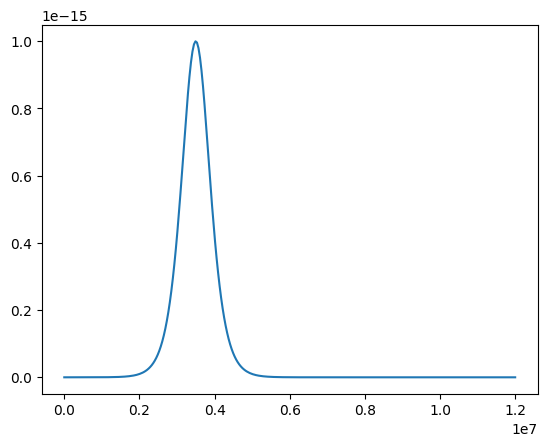

In [70]:
plt.plot(p_array,result_dk)
plt.pause(1)

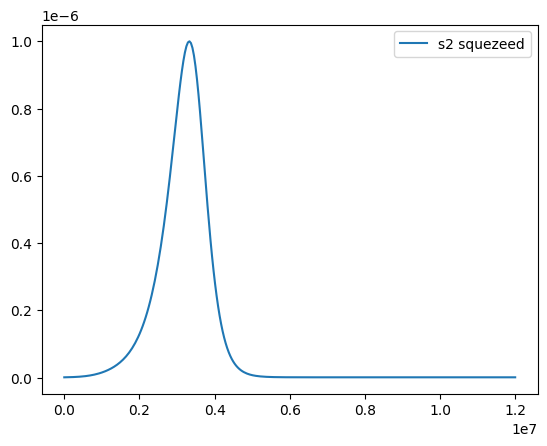

In [14]:
plt.plot(prev, s2, label = "s2 squezeed")
# plt.plot(prev, exprtk_eval, label = "ogs formula s2 squezeed")
plt.legend()
plt.pause(1)

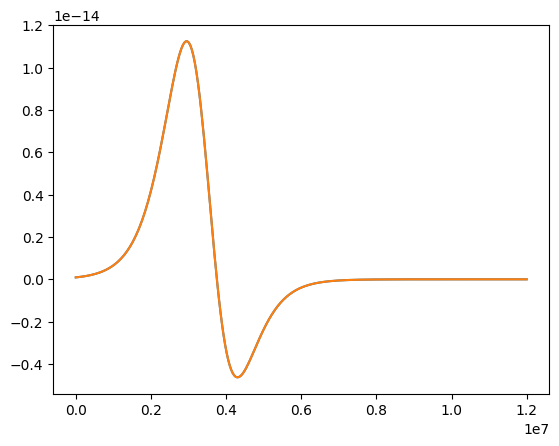

In [ ]:
plt.plot(p_array,result_ds)
plt.pause(1)

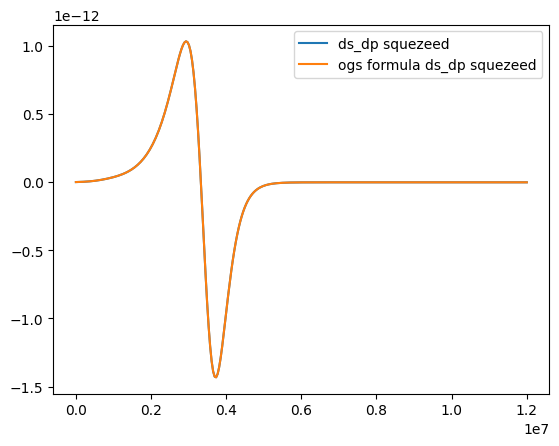

In [ ]:
plt.plot(prev, ds_dp, label = "ds_dp squezeed")
plt.plot(prev, exprtk_val_ds, label = "ogs formula ds_dp squezeed")
plt.legend()
plt.pause(1)

# Test prj mod

In [81]:
temp_prj(prj_in="BH10_20180718_40.6_SA_sf1_lh.prj",
         prj_out="BH10_20180718_40.6_SA_sf1_lh_updated.prj",
         factors= factors)